In [1]:
%load_ext autoreload
%autoreload 2

In [7]:
import sys
import os

sys.path.append("../..")

import json
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import dask
from dask.diagnostics import ProgressBar
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr

from cordex2energy.data_processing.load_data import ClimateModelData
from cordex2energy.utils.constants import EXTENT_CH, EXTENT_BC_MRRO
from cordex2energy.utils.utils_xarray import sel_extent

In [3]:
paths = json.load(open("../../paths_so4.json"))
path_data_processed = Path(paths["path_data_processed"])
path_data_temporary = Path(paths["path_data_temporary"])

In [4]:
dask.config.set(num_workers=10)
dask.config.set({"array.chunk-size": "500MiB"})


os.environ["OMP_NUM_THREADS"] = "1"  # OpenMP
os.environ["MKL_NUM_THREADS"] = "1"  # MKL
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # OpenBLAS
os.environ["NUMEXPR_NUM_THREADS"] = "1"  # numexpr

dask.config.set({"logging.distributed": "error"})
dask.config.set(num_workers=16, threads_per_worker=16)
dask.config.set({"array.chunk-size": "400MiB"})

dask.config.set({'distributed.worker.memory.target': 0.75})  # Spill to disk at 75% usage
dask.config.set({'distributed.worker.memory.spill': 0.8})   # Start spilling at 80%
dask.config.set({'distributed.worker.memory.pause': 0.9})   # Pause worker at 90%

# Load data

In [5]:
ds_rgs = xr.open_zarr(sorted(path_data_processed.glob("cordex_processed/*/prevah/rgs.zarr"))[-1], chunks="auto")

In [6]:
# ds_rgs_list = []
# for path in sorted(path_data_processed.glob("**/rgs.zarr")):
#     model = path.parent.parent.name
#     if "rcp45" in model:
#         continue
#     ds_rgs = xr.open_zarr(path, chunks="auto")
#     ds_rgs_list.append(ds_rgs.expand_dims({"model": [model]}))
# ds_rgs_all = xr.concat(ds_rgs_list, dim="model")
# del ds_rgs_list

In [7]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp26"
model_name = f"{climate_model_chain}_{climate_scenario}"
ds_rgs = xr.open_zarr(path_data_processed / f"cordex_processed/{model_name}/prevah/rgs.zarr", chunks="auto")
ds_rgs_m3s = ds_rgs * (500*500) / 1000 / (3600 * 24)

# Analysis

## MOHC-MOHC

### RCP8.5

In [7]:
with ProgressBar(dt=1):
    ds_rgs_yearly = ds_rgs["RGS"].sum(dim=["x", "y"]).resample(time="YE").sum().compute()

[########################################] | 100% Completed | 462.48 s


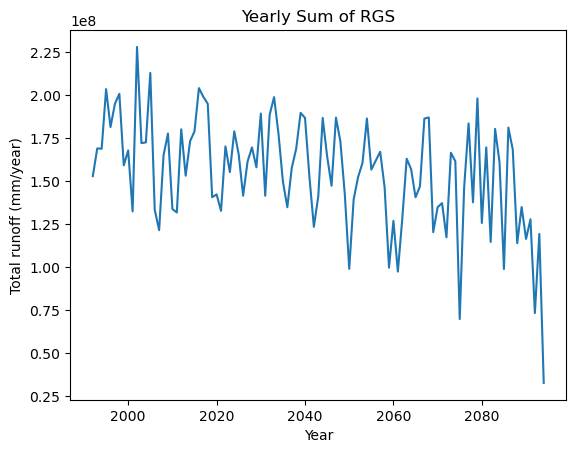

In [8]:
ds_rgs_yearly.plot()
plt.xlabel("Year")
plt.ylabel("Total runoff (mm/year)")
plt.title("Yearly Sum of RGS")
plt.show()

In [12]:
with ProgressBar(dt=1):
    ds_rgs_daily = ds_rgs["RGS"].sum(dim=["x", "y"]).compute()

[########################################] | 100% Completed | 29.05 s


In [13]:
# Filter for reference period (1991-2020)
ds_rgs_ref = ds_rgs_daily.sel(time=slice("1991-01-01", "2020-12-31"))

# Compute 99th percentile for reference period
p99_ref = ds_rgs_ref.quantile(0.99).values

print(f"99th percentile for reference period (1991-2020): {p99_ref:.2f} mm/day")

99th percentile for reference period (1991-2020): 1633489.93 mm/day


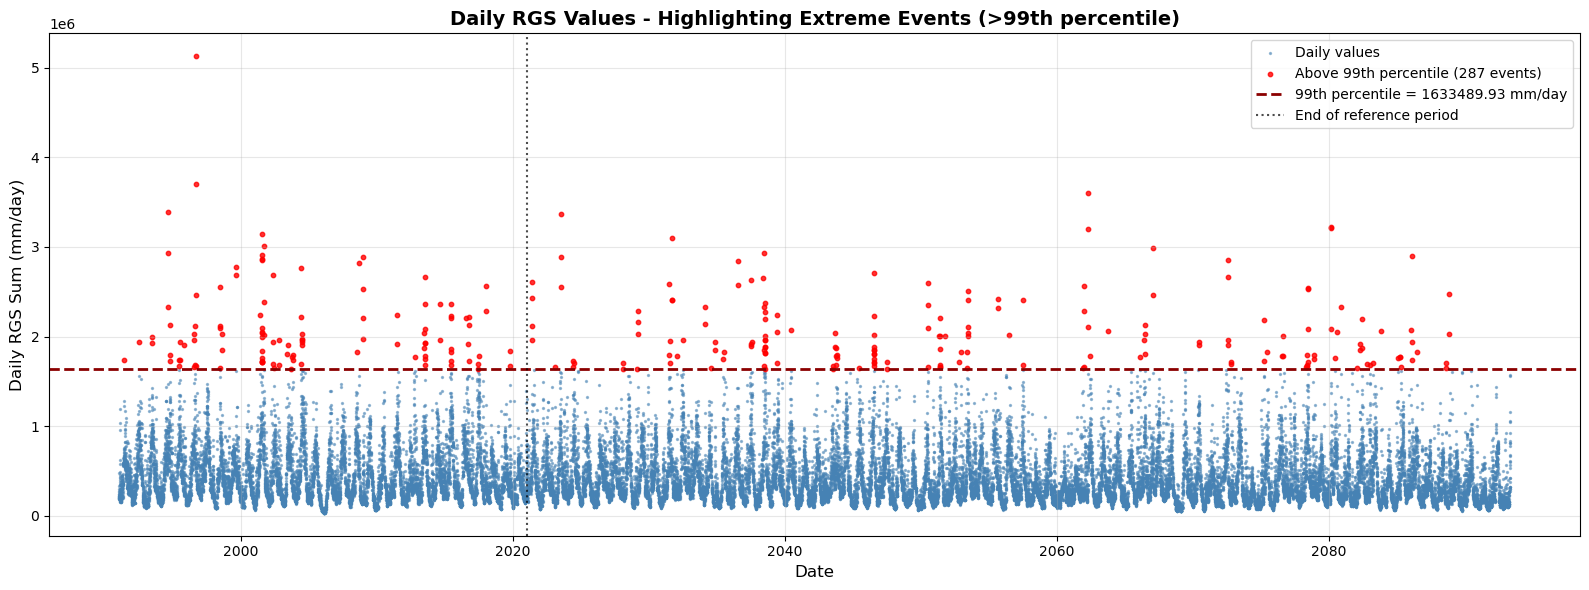


Statistics:
Total number of days: 37376
Days above 99th percentile: 287 (0.77%)
Days in reference period (1991-2020): 10958
Days above p99 in reference period: 110 (1.00%)
Days above p99 in future period: 177


In [ ]:
# Create plot with all daily values, highlighting values above 99th percentile
fig, ax = plt.subplots(figsize=(16, 6))

# Convert to pandas for easier plotting
df = ds_rgs_daily.to_dataframe(name='RGS_daily')

# Separate data into below and above threshold
below_p99 = df[df['RGS_daily'] <= p99_ref]
above_p99 = df[df['RGS_daily'] > p99_ref]

# Plot all points below threshold
ax.scatter(below_p99.index, below_p99['RGS_daily'],
           c='steelblue', s=2, alpha=0.5, label='Daily values')

# Highlight points above 99th percentile
ax.scatter(above_p99.index, above_p99['RGS_daily'],
           c='red', s=10, alpha=0.8, label=f'Above 99th percentile ({len(above_p99)} events)')

# Add horizontal line for 99th percentile
ax.axhline(y=p99_ref, color='darkred', linestyle='--', linewidth=2,
           label=f'99th percentile = {p99_ref:.2f} mm/day')

# Add vertical line for end of reference period
ax.axvline(x=pd.Timestamp('2020-12-31'), color='black', linestyle=':',
           linewidth=1.5, alpha=0.7, label='End of reference period')

ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Daily RGS Sum (mm/day)', fontsize=12)
ax.set_title('Daily RGS Values - Highlighting Extreme Events (>99th percentile)', fontsize=14, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print statistics
print("\nStatistics:")
print(f"Total number of days: {len(df)}")
print(f"Days above 99th percentile: {len(above_p99)} ({len(above_p99)/len(df)*100:.2f}%)")
print(f"Days in reference period (1991-2020): {len(ds_rgs_ref)}")
print(f"Days above p99 in reference period: {(ds_rgs_ref > p99_ref).sum().values} ({(ds_rgs_ref > p99_ref).sum().values/len(ds_rgs_ref)*100:.2f}%)")
print(f"Days above p99 in future period: {(ds_rgs_daily.sel(time=slice('2021', '2100')) > p99_ref).sum().values}")

## CNRM-CNRM

### RCP2.6 (comparison with CESM)

In [ ]:
path_routed_runoff = Path(paths["path_routed_runoff_argon"])
nb_folders = len(list((
        path_routed_runoff / "CNRM-26"
    ).glob("*/"))
)
list_q_routed = list(
    (
        path_routed_runoff / "CNRM-26"
    ).glob("*/Qrouted_historical_*_m3s.zarr")
)

if len(list_q_routed) != nb_folders or len(list_q_routed) == 0:
    raise ValueError(
        f"No routed runoff data found for {model_name} in {path_routed_runoff}"
    )

ds_routed = ClimateModelData(
    list_q_routed,
    chunks="auto",
    extent={"lat_min": EXTENT_BC_MRRO["lat_max"], "lat_max": EXTENT_BC_MRRO["lat_min"], "lon_min": EXTENT_BC_MRRO["lon_min"], "lon_max": EXTENT_BC_MRRO["lon_max"]},
    check_calendar=False,
)

In [22]:
with ProgressBar(dt=1):
    ds_rgs_yearly = ds_rgs["RGS"].sum(dim=["x", "y"]).resample(time="YE").sum().compute()
    ds_rgs_m3s_yearly = ds_rgs_m3s["RGS"].sum(dim=["x", "y"]).resample(time="YE").sum().compute()

[########################################] | 100% Completed | 180.17 s
[########################################] | 100% Completed | 46.18 s


In [23]:
with ProgressBar(dt=1):
    ds_rgs_m3s_weekly = ds_rgs_m3s["RGS"].sum(dim=["x", "y"]).resample(time="7D").sum().compute()

[########################################] | 100% Completed | 45.05 s


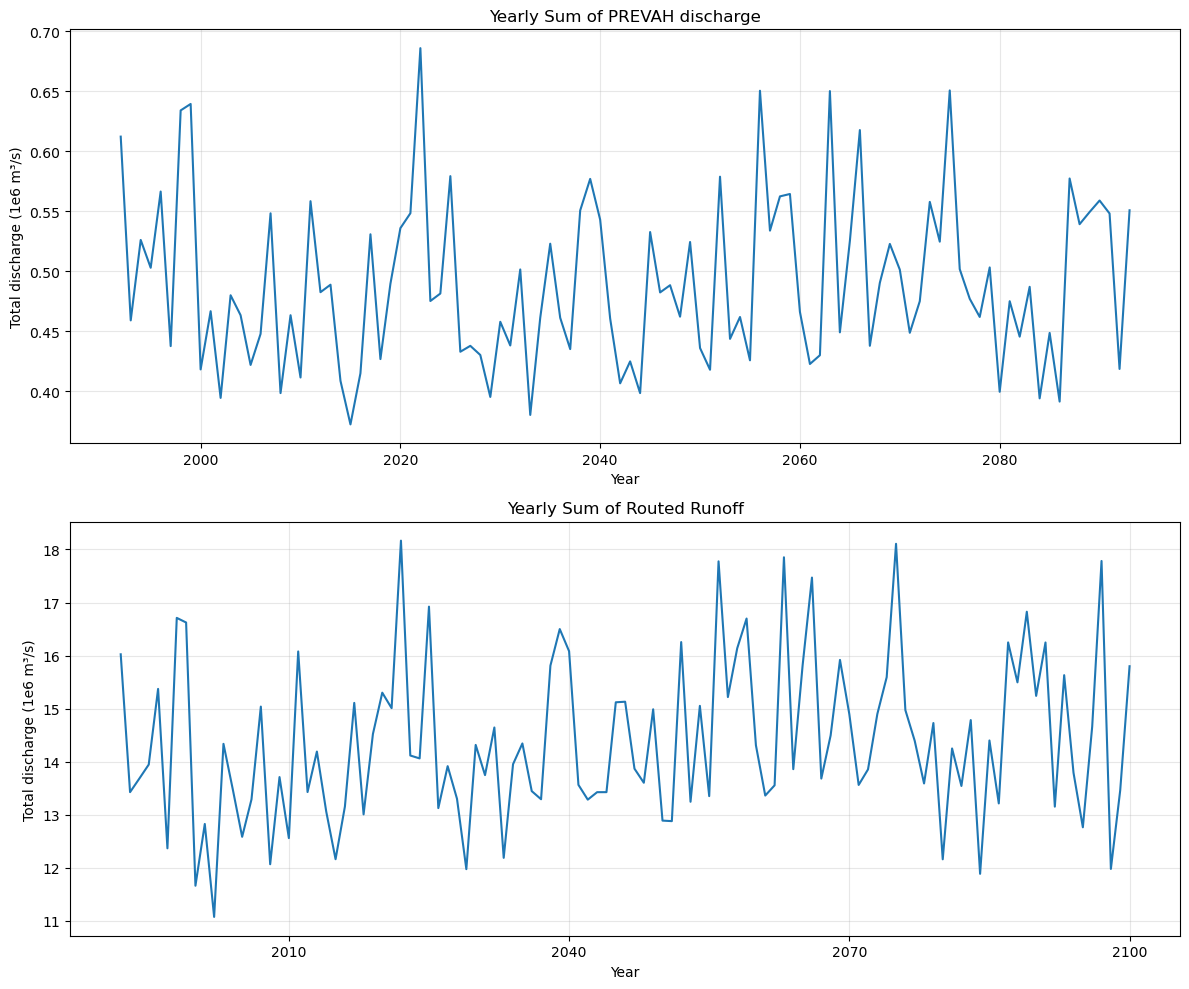

In [56]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Plot RGS yearly
(ds_rgs_m3s_yearly * 1e-6).plot(ax=axes[0])
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Total discharge (1e6 m³/s)")
axes[0].set_title("Yearly Sum of PREVAH discharge")
axes[0].grid(True, alpha=0.3)

# Plot routed runoff yearly
(ds_routed_yearly * 1e-6).plot(ax=axes[1])
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Total discharge (1e6 m³/s)")
axes[1].set_title("Yearly Sum of Routed Runoff")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### RCP8.5

In [ ]:
with ProgressBar(dt=1):
    ds_rgs_yearly = ds_rgs["RGS"].sum(dim=["x", "y"]).resample(time="YE").sum().compute()
    ds_rgs_m3s_yearly = ds_rgs_m3s["RGS"].sum(dim=["x", "y"]).resample(time="YE").sum().compute()

[########################################] | 100% Completed | 156.16 s
[########################################] | 100% Completed | 23.04 s


In [ ]:
with ProgressBar(dt=1):
    ds_rgs_daily = ds_rgs["RGS"].sum(dim=["x", "y"]).compute()

[                                        ] | 0% Completed | 727.59 us

[########################################] | 100% Completed | 18.04 s


In [9]:
# Filter for reference period (1991-2020)
ds_rgs_ref = ds_rgs_daily.sel(time=slice("1991-01-01", "2020-12-31"))

# Compute 99th percentile for reference period
p99_ref = ds_rgs_ref.quantile(0.99).values

print(f"99th percentile for reference period (1991-2020): {p99_ref:.2f} mm/day")

99th percentile for reference period (1991-2020): 1704083.15 mm/day


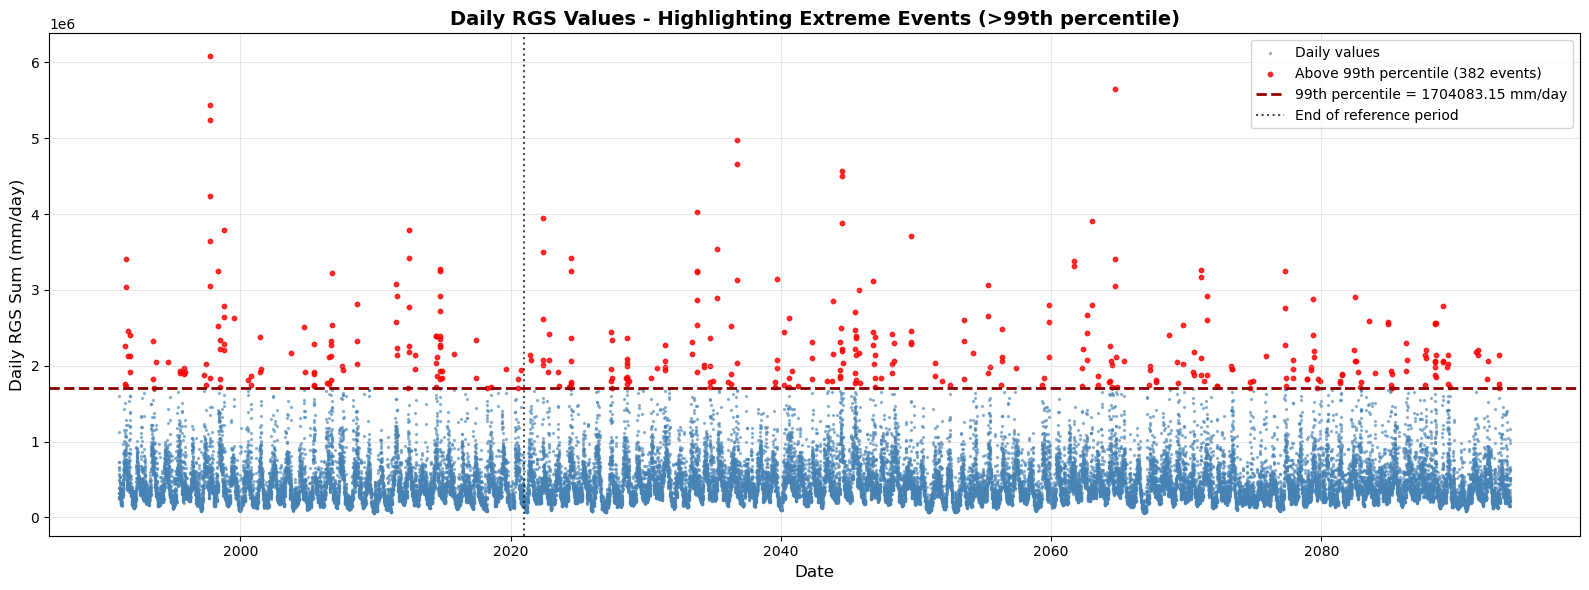


Statistics:
Total number of days: 37621
Days above 99th percentile: 382 (1.02%)
Days in reference period (1991-2020): 10958
Days above p99 in reference period: 110 (1.00%)
Days above p99 in future period: 272


In [10]:
# Create plot with all daily values, highlighting values above 99th percentile
fig, ax = plt.subplots(figsize=(16, 6))

# Convert to pandas for easier plotting
df = ds_rgs_daily.to_dataframe(name='RGS_daily')

# Separate data into below and above threshold
below_p99 = df[df['RGS_daily'] <= p99_ref]
above_p99 = df[df['RGS_daily'] > p99_ref]

# Plot all points below threshold
ax.scatter(below_p99.index, below_p99['RGS_daily'],
           c='steelblue', s=2, alpha=0.5, label='Daily values')

# Highlight points above 99th percentile
ax.scatter(above_p99.index, above_p99['RGS_daily'],
           c='red', s=10, alpha=0.8, label=f'Above 99th percentile ({len(above_p99)} events)')

# Add horizontal line for 99th percentile
ax.axhline(y=p99_ref, color='darkred', linestyle='--', linewidth=2,
           label=f'99th percentile = {p99_ref:.2f} mm/day')

# Add vertical line for end of reference period
ax.axvline(x=pd.Timestamp('2020-12-31'), color='black', linestyle=':',
           linewidth=1.5, alpha=0.7, label='End of reference period')

ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Daily RGS Sum (mm/day)', fontsize=12)
ax.set_title('Daily RGS Values - Highlighting Extreme Events (>99th percentile)', fontsize=14, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print statistics
print("\nStatistics:")
print(f"Total number of days: {len(df)}")
print(f"Days above 99th percentile: {len(above_p99)} ({len(above_p99)/len(df)*100:.2f}%)")
print(f"Days in reference period (1991-2020): {len(ds_rgs_ref)}")
print(f"Days above p99 in reference period: {(ds_rgs_ref > p99_ref).sum().values} ({(ds_rgs_ref > p99_ref).sum().values/len(ds_rgs_ref)*100:.2f}%)")
print(f"Days above p99 in future period: {(ds_rgs_daily.sel(time=slice('2021', '2100')) > p99_ref).sum().values}")

In [ ]:
ds_q_routed =